In [1]:
from urllib.request import urlopen
import numpy as np

url = 'https://s3.amazonaws.com/openneuro/ds000031/ds000031_R1.0.2/' \
      'uncompressed/derivatives/sub-01/ses-073/' \
      'sub-01_ses-073_task-rest_run-001_parcel-timeseries.txt'
data = np.loadtxt(urlopen(url).readlines())
print(data.shape)

# Data has 518 timepoints, 630 regions of interest (ROI)

(518, 630)


In [4]:
data.T

array([[ 0.14371604, -0.89511144, -2.1950352 , ..., -0.96507622,
        -1.3823281 , -1.6994226 ],
       [ 2.5132383 ,  2.8119079 ,  2.3928552 , ...,  1.0010792 ,
         1.2329445 ,  1.498042  ],
       [-1.5129048 , -1.2094362 , -0.60246287, ..., -0.01580902,
        -0.09555487, -0.06539684],
       ...,
       [ 0.39230374,  0.36760339,  0.61872321, ...,  0.81372797,
        -0.61790156, -1.72327471],
       [ 0.56165248,  0.65420479,  0.95188111, ...,  0.49923116,
         0.34682173,  0.57918566],
       [-3.54204488, -3.22383714, -2.86043358, ..., -0.37552482,
        -0.60588783, -0.89505953]])

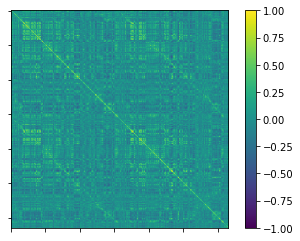

In [3]:
# Plot ROIxROI correlation matrix

import matplotlib.pyplot as plt

corr = np.corrcoef(data.T)

fig, ax = plt.subplots(1, 1)
coll = ax.imshow(corr, vmin=-1, vmax=1, cmap='viridis')
ax.set(xticklabels=[], yticklabels=[])
fig.colorbar(coll)

In [7]:
# Use louvain to find structure in correlation network
# Non-negative edges/correlations only
# change all negative correlations to 0

import bct

nonegative = corr.copy()
nonegative[corr < 0] = 0

# Resolution limit 1.5
ci, Q = bct.community_louvain(nonegative, gamma=1.5)
# number of communities
num_ci = len(np.unique(ci))
print('{} clusters detected with a modularity of {:.2f}.'\
      .format(num_ci, Q))

8 clusters detected with a modularity of 0.25.


<AxesSubplot:>

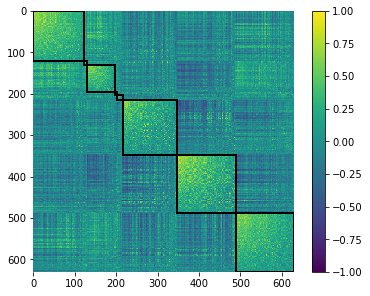

In [8]:
# plot_mod_heatmap() is wrapper around plt.imshow()

from netneurotools import plotting

plotting.plot_mod_heatmap(corr, ci, vmin=-1, vmax=1, cmap='viridis')

[Text(0, 0.5, 'Assignments'),
 Text(0.5, 0, 'ROIs'),
 [Text(-100.0, 0, ''),
  Text(0.0, 0, ''),
  Text(100.0, 0, ''),
  Text(200.0, 0, ''),
  Text(300.0, 0, ''),
  Text(400.0, 0, ''),
  Text(500.0, 0, ''),
  Text(600.0, 0, ''),
  Text(700.0, 0, '')],
 [Text(0, -20.0, ''),
  Text(0, 0.0, ''),
  Text(0, 20.0, ''),
  Text(0, 40.0, ''),
  Text(0, 60.0, ''),
  Text(0, 80.0, ''),
  Text(0, 100.0, '')]]

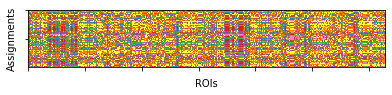

In [9]:
# The Louvain algorithm is greedy so different instantiations 
# will return different community assignments. 

# Repeat louvain 100 times
ci = [bct.community_louvain(nonegative, gamma=1.5)[0] \
      for n in range(100)]

# Create plot of modules ~ ROIs
fig, ax = plt.subplots(1, 1, figsize=(6.4, 2))
ax.imshow(ci, cmap='Set1')
ax.set(ylabel='Assignments', xlabel='ROIs', \
       xticklabels=[], yticklabels=[])

<AxesSubplot:>

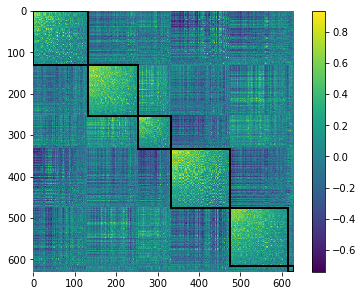

In [16]:
# Get consensus using Netneurotools
from netneurotools import cluster
# np.column_stack(ci) stacks 1-D arrays as columns into 2-D array

consensus = cluster.find_consensus(np.column_stack(ci), seed=1234)
# len(np.unique(consensus)) gives 6 modules
plotting.plot_mod_heatmap(corr, consensus, cmap='viridis')